## Data Preparation

In [1]:
import torch
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq

import matplotlib.pyplot as plt

from pathlib import Path
from tqdm.autonotebook import tqdm

from hyperspot.metadata import ProjectMetadata
from hyperspot.preprocessing import common, singlecell, kidneycancer
from hyperspot.preprocessing import visium
from hyperspot.utils import load_ct_spatial_data, save_orig_st_data, save_decomposed_st_data

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/numcodecs/__init__.py:106: DeprecationWarning: crc32c usage is deprecated since numcodecs v0.16.4. It is recommended to install google_crc32c instead.
  from numcodecs.checksum32 import CRC32, Adler32, JenkinsLookup3
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFou

Identify source and results directories

In [2]:
results_dir = Path("hyperspot_project_files")
project_name = "Human Kidney Cancer Core"

project_files_dir = results_dir / project_name
project_files_dir.mkdir(parents=True, exist_ok=True)

In [3]:
spotiphy_proj_dir = Path("spotiphy_project_files") / project_name

Load deconvolution results and spatial transcriptomics data.

Spatial transcriptomics data contains spot ids and spot locations, which are requirements for creating hyperedges.

In [4]:
adata_decomp = sc.read_h5ad(spotiphy_proj_dir / "ST_decomposition.h5ad")
adata_st = sc.read_h5ad(spotiphy_proj_dir / "Human Kidney Cancer Core.h5ad")

The generated cell decomposition data does not yet include the cell locations generated by Spotiphy.
For visualization using Squidpy, we update adata with the generated locations.

In [5]:
adata_decomp = common.add_generated_cell_locations(spotiphy_proj_dir, adata_decomp, adata_st)

Prepared hires segmentation: (1834, 2000), 27719 cells


In [6]:
common_genes = set(adata_st.var_names).intersection(set(adata_decomp.var_names))
len(common_genes)

10849

### Make Project Metadata File

Generate a `ProjectMetadata` object. The `ProjectMetadata` file contains metadata about the project, which is used in several parts of the pipeline:
- `project_folder` - directory of the project.
- `ct_key` - cell type key used by adata objects to indicate the cell type of each cell.
- `ct_list` - list of cell types sorted in lexicographical order.
- `ct_mapping` - mapping of cell type names (`str`) to their positions in the `ct_list` (`int`). `ct_mapping` is important when preparing and accessing data in the pipeline.
- `n_cell_types` - number of cell types in the data.
- `dir_map` - mapping of directories to project subfolders

Creating `ProjectMetadata` requires `ct_key` as an argument, but once created, `ct_key` can also be accessed from the `ProjectMetadata`.

In [7]:
project_metadata = ProjectMetadata.create(project_files_dir, 
                             adata_decomp,
                             'cell_type')
# ct_metadata.ct_key, ct_metadata.ct_list, ct_metadata.ct_mapping, ct_metadata.n_cell_types

In [8]:
project_metadata.dir_map

{'attr_dir': 'attribution',
 'classifier_dir': 'classifiers',
 'clustering_dir': 'clustering',
 'ct_data_dir': 'ct_spatial_data',
 'plot_dir': 'plots',
 'eval_dir': 'evaluation',
 'domain_markers_dir': 'domain_markers'}

## Preprocessing

Preprocess original and decomposed ST data.

### General Preprocessing
Preprocess original ST data using standard preprocessing steps. Also perform HVG selection.

In [9]:
# Preprocessing and HVG detection
n_top_genes = 3000

# filter first before preprocess
print(adata_decomp.shape)
print(adata_st.shape)
adata_decomp = common.filter(adata_decomp, min_genes=20, min_locs=20)
adata_st = common.filter(adata_st, min_genes=20, min_locs=20)
print(adata_decomp.shape)
print(adata_st.shape)

# Preprocess ST data.
# Store unprocessed data to raw.
# Raw data is needed for visualization.
adata_st.raw = adata_st.copy()
sc.pp.highly_variable_genes(adata_st, flavor='seurat_v3', n_top_genes=n_top_genes)
sc.pp.normalize_total(adata_st, target_sum=1e6)
sc.pp.log1p(adata_st)

(27719, 10849)
(3008, 15222)
(27094, 10800)
(2947, 12774)


Save the preprocessed ```adata_decomp``` and ```adata_st``` in the project folder 

In [10]:
# save adata_st
save_orig_st_data(adata_st)

# save adata_decomp
save_decomposed_st_data(adata_decomp)
# adata_decomp.write_h5ad(project_files_dir / "ST_decomposition.h5ad")

### Create separate anndata objects for each cell type.

For the decomposed data, we first separate them into different anndata objects per cell type using `preprocessing.singlecell.make_ct_spatial_data`, which also performs preprocessing on each anndata object separately. 

Then, get the top genes per cell type using `preprocessing.singlecell.perform_ct_feature_selection`.

In [11]:
n_features=3000
# singlecell.make_ct_spatial_adata(adata_decomp)
# singlecell.perform_ct_feature_selection(n_features=n_features)

Visualize the resulting anndata objects.

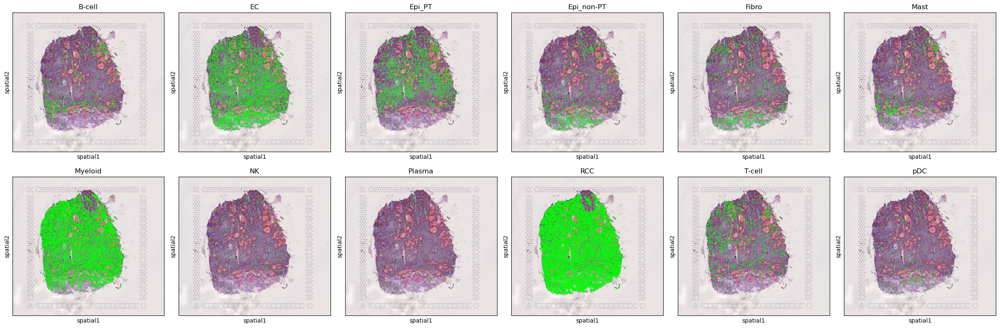

In [12]:
from hyperspot.visualization import plot_all_ct_decomposition, plot_ct_decomposition
plot_all_ct_decomposition(n_cols=6)

# use this to plot each cell type separately
# plot_ct_decomposition(display=False, show_title=False)

Also visualize the distribution of genes on the original ST anndata object.

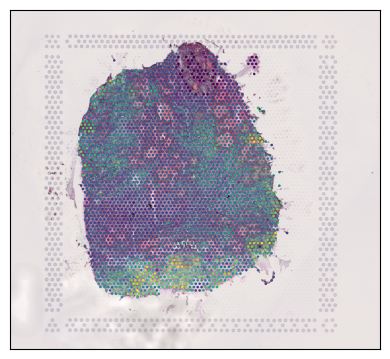

In [13]:
from hyperspot.visualization import plot_st_gene_counts

plot_st_gene_counts(show_title=False, display=True)

## ML Dataset Creation

Create the Hypergraph Data for the ML pipeline.

In [14]:
# hgdata = visium.create_hypergraph_data(
#     adata_st, 
#     n_features=n_features, 
#     num_neighbor_spots=7, 
#     intra_weight=5,
#     n_hyperedge_feats=n_features)
# hgdata.save()

# HyperSpot Pipeline

For each step of the pipeline, run the following commands:

## I. Embedding Learning

```bash
# Using CUDA
CUDA_VISIBLE_DEVICES=1 hyperspot train-embedder --project "Human Kidney Cancer Core" \
--model.model-name HyFiEmbedder --model.input-dim 3000 --model.embedding-dim 50 --model.dropout 0.2 \
--trainer.num_epochs 1000 --trainer.batch_size 22431 --trainer.accelerator cuda
```

```bash
# Using CPU
hyperspot train-embedder --project "Human Kidney Cancer Core" \
--model.model-name HyFiEmbedder --model.input-dim 3000 --model.embedding-dim 50 --model.dropout 0.2 \
--trainer.num_epochs 1000 --trainer.batch_size 22431 --trainer.accelerator cpu
```

## II. Embedding Generation

```bash
# Using CUDA
CUDA_VISIBLE_DEVICES=1 hyperspot make-embedding --project "Human Kidney Cancer Core" \
--model.model-name HyFiEmbedder --model.input-dim 3000 --model.embedding-dim 50 --model.dropout 0.2 \
--trainer.num_epochs 100 --trainer.batch_size 22431 --trainer.accelerator cuda
```

```bash
# Using CPU
hyperspot make-embedding --project "Human Kidney Cancer Core" \
--model.model-name HyFiEmbedder --model.input-dim 3000 --model.embedding-dim 50 --model.dropout 0.2 \
--trainer.num_epochs 100 --trainer.batch_size 22431 --trainer.accelerator cpu
```

## III. Spatial Domain Identification

```bash
hyperspot compute-spatial-domains --project "Human Kidney Cancer Core" 
```

## IV. Cell-type Specific Domain Identification

```bash
hyperspot compute-celltype-spatial-domains --project "Human Kidney Cancer Core" \
--data.cell-type-key "cell_type"
```

## V. Classifier Training

```bash
# Using CUDA
CUDA_VISIBLE_DEVICES=1 hyperspot train-celltype-domain-classifiers --project "Human Kidney Cancer Core" \
--classifier.embedding-dim 50 --classifier.num_layers 3 \
--trainer.num_epochs 1000 --trainer.batch_size 4096 --trainer.accelerator cuda
```

```bash
# Using CPU
hyperspot train-classifier --project "Human Kidney Cancer Core" \
--classifier.embedding-dim 50 --classifier.num_layers 3 \
--trainer.num_epochs 1000 --trainer.batch_size 4096 --trainer.accelerator cpu
```

## VI. Spatial Metagene Computation

### A. Compute Metagene Attribution to a Cell Type Spatial Domain
```bash
# Using CUDA
CUDA_VISIBLE_DEVICES=1 hyperspot compute-cell-embedding-attributions --project "Human Kidney Cancer Core" \
--cell_type EC \
--classifier.embedding-dim 50 --classifier.num_layers 3 \
--attribution.n_steps 1000 --attribution.accelerator cuda
```

```bash
# Using CPU
hyperspot compute-cell-embedding-attributions --project "Human Kidney Cancer Core" \
--cell_type EC \
--classifier.embedding-dim 50 --classifier.num_layers 3 \
--attribution.n_steps 1000 --attribution.accelerator cpu
```

### B. Compute Gene Attribution to Metagene

```bash
# Train Embedder
CUDA_VISIBLE_DEVICES=0 hyperspot train-embedder --project "Human Kidney Cancer Core" --model.model-name CTHGCAEv4Embedder --model.input-dim 3000 --model.embedding-dim 200 --model.latent-dim 500 --model.dropout 0.2 --trainer.num_epochs 1000 --trainer.batch_size 27094 --trainer.accelerator cuda --regularizer.optimize-hyperedges --regularizer.rho-h 1.0

# --regularizer.lambda-var 0.25 --regularizer.lambda-cov 0.1 --regularizer.reg-weight 1e-3   --regularizer.lambda-var-h 0.1 --regularizer.lambda-cov-h 0.05

# Make Embedding
CUDA_VISIBLE_DEVICES=0 hyperspot make-embedding --project "Human Kidney Cancer Core" --model.model-name CTHGCAEv4Embedder --model.input-dim 3000 --model.embedding-dim 200 --model.latent-dim 500 --model.dropout 0.2 --trainer.num_epochs 1000 --trainer.batch_size 27094 --trainer.accelerator cuda
# Compute Tissue-Wide Spatial Domains
hyperspot compute-spatial-domains --project "Human Kidney Cancer Core" --clustering.min_cluster_pct 0.05 --clustering.algorithm agglomerative --clustering.n-pca-components 50
# Compute Cell-Type-Specific Spatial Domains
hyperspot compute-celltype-spatial-domains --project "Human Kidney Cancer Core" --clustering.min_cluster_pct 0.05 --clustering.algorithm agglomerative --clustering.n-pca-components 50


# CUDA_VISIBLE_DEVICES=0 hyperspot train-celltype-domain-classifiers --project "Human Kidney Cancer Core" --classifier.embedding-dim 200 --classifier.num_layers 3 --trainer.num_epochs 1000 --trainer.batch_size 4096 --trainer.accelerator cuda
# CUDA_VISIBLE_DEVICES=0 hyperspot compute-gene-to-celltype-domain-attribution --project "Human Kidney Cancer Core" --cell-type RCC --model.model-name CTHGCAEEmbedder --model.input-dim 3000 --model.embedding-dim 200 --model.latent-dim 500 --classifier.embedding-dim 200 --classifier.num_layers 3 --explainer.n_steps 100 --explainer.batch-size 8192 --explainer.accelerator cuda

# Perform Model Evaluation
CUDA_VISIBLE_DEVICES=1 hyperspot perform-model-evaluation --project "Human Kidney Cancer Core" --model.model-name CTHGCAEEmbedder --model.input-dim 3000 --model.embedding-dim 200 --model.latent-dim 500 --model.dropout 0.2 --trainer.num_epochs 1000 --trainer.batch_size 27094 --trainer.accelerator cuda --clustering.min_cluster_pct 0.05 --clustering.algorithm leiden --num_runs 10

# CUDA_VISIBLE_DEVICES=0 hyperspot compute-cell-embedding-attributions --project "Human Kidney Cancer Core" --classifier.embedding-dim 200 --classifier.num_layers 3 --explainer.n_steps 1000 --explainer.accelerator cuda
# CUDA_VISIBLE_DEVICES=0 hyperspot compute-metagene-to-region-attribution --project "Human Kidney Cancer Core" --cell-type EC --region 0 --classifier.embedding-dim 200 --classifier.num_layers 3 --explainer.n_steps 1000 --explainer.accelerator cuda
# CUDA_VISIBLE_DEVICES=0 hyperspot compute-gene-to-cell-metagene-attribution --project "Human Kidney Cancer Core" --model.model-name SpatialFusionEmbedder --model.input-dim 3000 --model.embedding-dim 200 --model.latent-dim 500 --explainer.n_steps 100 --explainer.batch-size 8192 --explainer.accelerator cuda

```

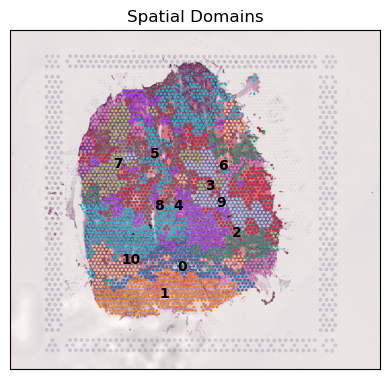

In [15]:
from hyperspot.visualization import plot_aggr_st_domains

plot_aggr_st_domains(show_title=False)
plot_aggr_st_domains(show_title=True, display=True, save=False)

In [16]:
adata_decomp.obs_names

Index(['0', '1', '2', '3', '4', '5', '6', '7', '8', '9',
       ...
       '27707', '27708', '27709', '27711', '27712', '27713', '27714', '27715',
       '27716', '27718'],
      dtype='object', length=27094)

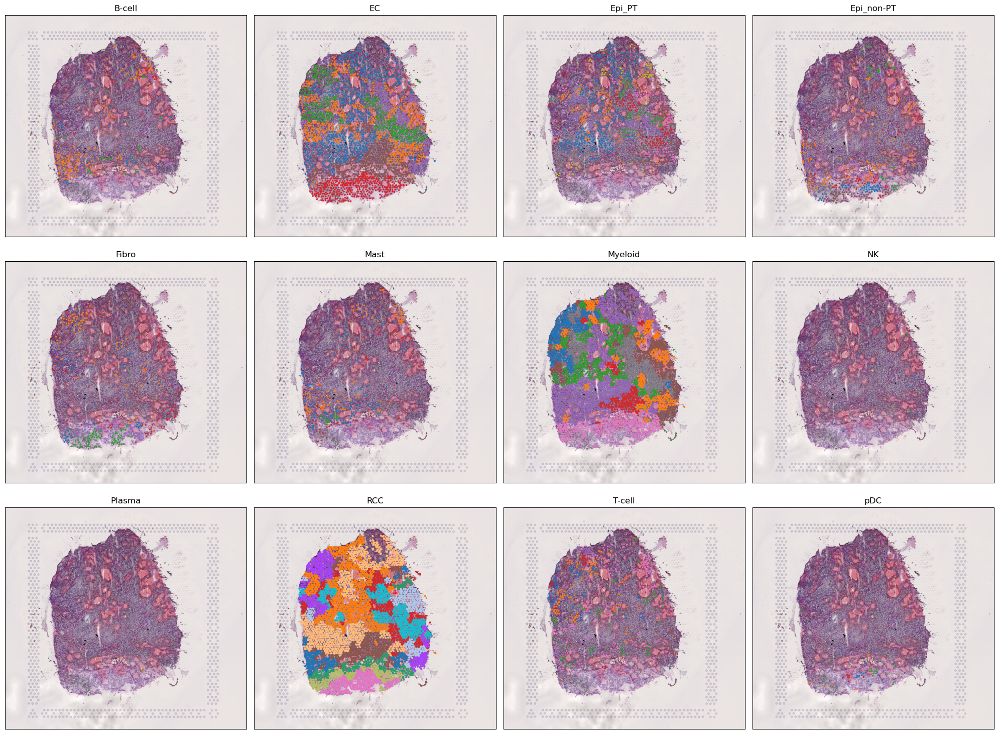

In [17]:
from hyperspot.visualization import plot_all_ct_domains

plot_all_ct_domains()

In [18]:
from hyperspot.visualization import plot_ct_domains
plot_ct_domains(show_title=True)

/workspace/HGCTSVG/hgctsvg/src/hgctsvg/visualization/ct.py:154: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
/workspace/HGCTSVG/hgctsvg/src/hgctsvg/visualization/ct.py:154: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
/workspace/HGCTSVG/hgctsvg/src/hgctsvg/visualization/ct.py:154: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
/workspace/HGCTSVG/hgctsvg/src/hgctsvg/visualization/ct.py:154: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
/workspace/HGCTSVG/hgctsvg/src/hgctsvg/visualization/ct.py:154: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
/workspace/HGCTSVG/hgctsvg/src/hgctsvg/visualization/ct.py:154: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
/workspace/HGCTSVG/hgctsvg/src/hgctsvg/visualization/ct.py:154: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
/workspace/HGCTSVG/hgctsvg/src/hgctsvg/vi

In [19]:
from hyperspot.utils import load_aggr_st_data

adata_aggr = load_aggr_st_data()
adata_aggr.obs['domain'].value_counts()

domain
8     547
3     336
1     332
4     314
5     274
2     213
7     204
0     183
9     163
10    160
6     148
Name: count, dtype: int64

In [20]:
adata_aggr.obs['domain'].astype(int).tolist()

[2,
 10,
 8,
 6,
 8,
 8,
 1,
 4,
 8,
 9,
 1,
 1,
 4,
 8,
 8,
 7,
 1,
 1,
 0,
 7,
 7,
 8,
 5,
 2,
 3,
 9,
 10,
 4,
 3,
 2,
 1,
 8,
 2,
 7,
 8,
 8,
 5,
 5,
 4,
 10,
 6,
 5,
 8,
 5,
 1,
 7,
 2,
 8,
 4,
 10,
 8,
 3,
 6,
 1,
 1,
 4,
 7,
 8,
 10,
 1,
 9,
 8,
 9,
 3,
 8,
 6,
 0,
 10,
 2,
 5,
 2,
 6,
 1,
 7,
 2,
 2,
 8,
 8,
 5,
 10,
 3,
 6,
 5,
 0,
 4,
 0,
 7,
 3,
 8,
 8,
 3,
 8,
 5,
 7,
 6,
 8,
 7,
 1,
 8,
 9,
 7,
 3,
 5,
 9,
 0,
 6,
 0,
 0,
 7,
 1,
 1,
 10,
 4,
 9,
 0,
 8,
 8,
 3,
 6,
 5,
 5,
 1,
 6,
 10,
 2,
 3,
 8,
 3,
 9,
 4,
 1,
 6,
 9,
 8,
 1,
 2,
 10,
 8,
 5,
 1,
 3,
 8,
 8,
 5,
 1,
 0,
 4,
 0,
 3,
 4,
 4,
 1,
 2,
 3,
 6,
 9,
 8,
 10,
 2,
 3,
 10,
 8,
 3,
 8,
 7,
 2,
 7,
 2,
 7,
 5,
 10,
 1,
 8,
 0,
 4,
 2,
 1,
 1,
 4,
 3,
 1,
 2,
 3,
 3,
 5,
 3,
 4,
 5,
 0,
 4,
 5,
 3,
 8,
 10,
 2,
 7,
 8,
 3,
 9,
 8,
 10,
 5,
 1,
 8,
 3,
 9,
 5,
 0,
 8,
 8,
 8,
 6,
 8,
 5,
 8,
 8,
 7,
 7,
 0,
 9,
 4,
 4,
 3,
 8,
 3,
 0,
 8,
 0,
 5,
 0,
 8,
 4,
 3,
 4,
 5,
 2,
 5,
 8,
 5,
 2,
 7,
 3,
 0,
 1,
 0,
 3,
 

In [21]:
adata_st2 = adata_st[adata_aggr.obs_names]
adata_st2

View of AnnData object with n_obs × n_vars = 2874 × 12774
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', 'donor_id', 'region', 'n_genes'
    var: 'feature_types', 'genome', 'SYMBOL', 'mt', 'n_cells_by_counts-6800STDY12499410', 'mean_counts-6800STDY12499410', 'log1p_mean_counts-6800STDY12499410', 'pct_dropout_by_counts-6800STDY12499410', 'total_counts-6800STDY12499410', 'log1p_total_counts-6800STDY12499410', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'sample_colors', 'spatial', 'hvg', 'log1p'
    obsm: 'spatial'

In [22]:
import torch
embedding = torch.load(project_metadata.project_folder / "hyperedge_embeddings.pth")

nan_mask = torch.isnan(embedding)
nan_rows = torch.any(nan_mask, dim=1)
embedding = embedding[~nan_rows]
embedding = embedding.numpy()
adata_st2.obsm['embedding'] = embedding
adata_st2.obs['domain_embedding'] = adata_aggr.obs['domain']

/tmp/ipykernel_3573775/1069502697.py:8: ImplicitModificationWarning: Setting element `.obsm['embedding']` of view, initializing view as actual.
  adata_st2.obsm['embedding'] = embedding


In [23]:
adata_st2

AnnData object with n_obs × n_vars = 2874 × 12774
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', 'donor_id', 'region', 'n_genes', 'domain_embedding'
    var: 'feature_types', 'genome', 'SYMBOL', 'mt', 'n_cells_by_counts-6800STDY12499410', 'mean_counts-6800STDY12499410', 'log1p_mean_counts-6800STDY12499410', 'pct_dropout_by_counts-6800STDY12499410', 'total_counts-6800STDY12499410', 'log1p_total_counts-6800STDY12499410', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'sample_colors', 'spatial', 'hvg', 'log1p'
    obsm: 'spatial', 'embedding'

In [24]:
adata_st2.uns.keys()

dict_keys(['sample_colors', 'spatial', 'hvg', 'log1p'])

In [25]:
sc.pp.neighbors(adata_st2)
sc.tl.leiden(adata_st2)

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/scanpy/neighbors/__init__.py:577: UserWarning: You’re trying to run this on 12774 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  x = _choose_representation(self._adata, use_rep=use_rep, n_pcs=n_pcs)
/tmp/ipykernel_3573775/3072798649.py:2: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata_st2)


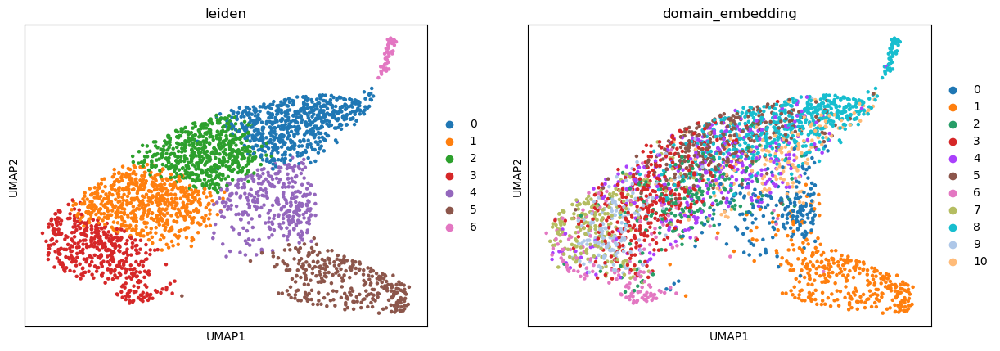

In [26]:
sc.tl.umap(adata_st2)
sc.pl.umap(adata_st2, color=['leiden', 'domain_embedding'])

In [27]:
sc.tl.rank_genes_groups(adata_aggr, 
                        groupby='domain',
                        method="wilcoxon",
                        pts=True,
                        use_raw=False)

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/scanpy/tools/_dendrogram.py:138: UserWarning: You’re trying to run this on 10800 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  _choose_representation(adata, use_rep=use_rep, n_pcs=n_pcs)


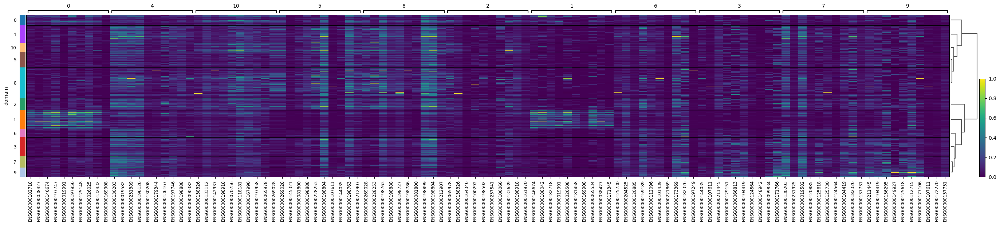

In [28]:
sc.tl.dendrogram(adata_aggr, groupby='domain')
sc.pl.rank_genes_groups_heatmap(
    adata_aggr,
    n_genes=10,
    standard_scale="var",
    show_gene_labels=True,
)

In [29]:
adata_RCC = load_ct_spatial_data("RCC")
adata_RCC

AnnData object with n_obs × n_vars = 12648 × 10684
    obs: 'cell_type', 'spot_name', 'n_cell', 'location_x', 'location_y', 'library_id', 'segmentation', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'n_genes', 'cell_idx', 'domain'
    var: 'SYMBOL', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'feature_gene'
    uns: 'cell_count', 'hvg', 'log1p', 'sample_colors', 'spatial'
    obsm: 'cell_nucleus', 'embedding', 'embedding_pca', 'spatial'

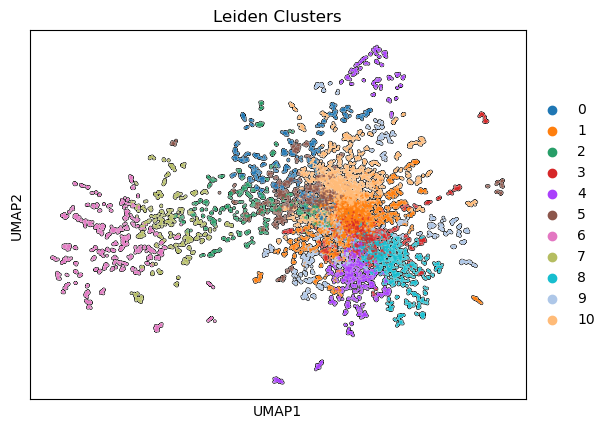

In [31]:
from scipy import sparse

sc.pp.neighbors(adata_RCC, use_rep='embedding', knn=False, method='gauss', key_added='embedding')
adata_RCC.obsp['embedding_connectivities'] = sparse.csr_matrix(adata_RCC.obsp['embedding_connectivities'])
sc.tl.umap(adata_RCC, neighbors_key='embedding')
sc.pl.umap(adata_RCC, color='domain', title='Leiden Clusters', neighbors_key='embedding', add_outline=True)

In [32]:
adata_decomp

AnnData object with n_obs × n_vars = 27094 × 10800
    obs: 'cell_type', 'spot_name', 'n_cell', 'location_x', 'location_y', 'library_id', 'segmentation', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'n_genes'
    var: 'SYMBOL', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'cell_count', 'sample_colors', 'spatial'
    obsm: 'cell_nucleus', 'spatial'

In [33]:
adata_RCC

AnnData object with n_obs × n_vars = 12648 × 10684
    obs: 'cell_type', 'spot_name', 'n_cell', 'location_x', 'location_y', 'library_id', 'segmentation', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'n_genes', 'cell_idx', 'domain'
    var: 'SYMBOL', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'feature_gene'
    uns: 'cell_count', 'hvg', 'log1p', 'sample_colors', 'spatial', 'umap', 'embedding', 'domain_colors'
    obsm: 'cell_nucleus', 'embedding', 'embedding_pca', 'spatial', 'X_umap'
    obsp: 'umap_distances', 'umap_connectivities', 'embedding_distances', 'embedding_connectivities'

In [34]:
adata_RCC.obs['domain'].value_counts()

domain
10    2327
1     2213
8     1203
4     1053
6     1028
5     1010
9      886
3      868
2      716
0      705
7      639
Name: count, dtype: int64

In [35]:
sc.tl.rank_genes_groups(adata_RCC, 
                        groupby='domain',
                        method="wilcoxon",
                        pts=True,
                        use_raw=False)

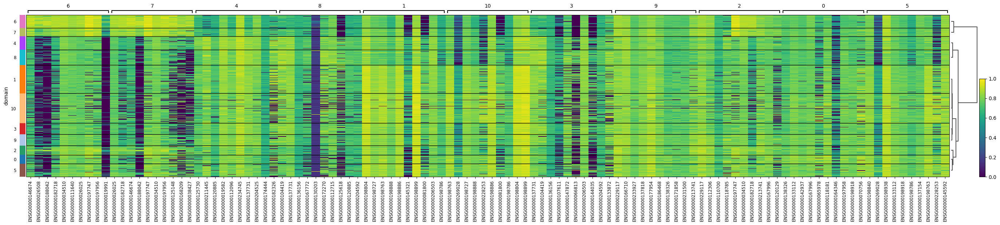

In [36]:
# sc.tl.dendrogram(adata_RCC, groupby='leiden')
sc.tl.dendrogram(adata_RCC, var_names=adata_RCC.var_names[adata_RCC.var['feature_gene']], groupby='domain')
sc.pl.rank_genes_groups_heatmap(
    adata_RCC,
    n_genes=10,
    standard_scale="var",
    # standard_scale="obs",
    # vmin=adata_RCC.X[adata_RCC.X > 0].min(),
    log=True,
    show_gene_labels=True,
)

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/scanpy/tools/_dendrogram.py:138: UserWarning: You’re trying to run this on 10684 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  _choose_representation(adata, use_rep=use_rep, n_pcs=n_pcs)


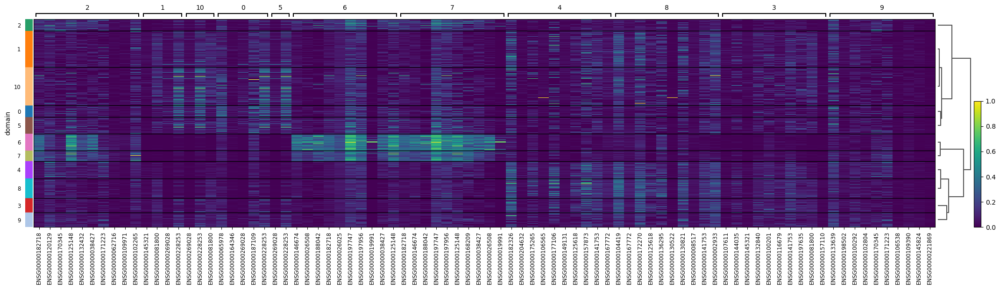

In [37]:
from hyperspot.pipeline import compute_domain_ct_svgs, create_svg_list
from hyperspot.visualization import plot_ct_marker_groups_heatmap

top_genes_RCC = compute_domain_ct_svgs("RCC", rank_by='scores')
plot_ct_marker_groups_heatmap(adata_RCC, top_genes_RCC)

In [38]:
top_genes_RCC

{'0':               names     scores  logfoldchanges          pvals      pvals_adj  \
 4   ENSG00000065978  28.759632        2.336311  6.863916e-182  1.466682e-178   
 6   ENSG00000164346  25.172812        3.053505  7.953109e-140  1.062138e-136   
 10  ENSG00000269028  23.691742        2.312569  4.386632e-124  3.605136e-121   
 31  ENSG00000187109  18.542465        1.735159   9.381970e-77   2.863913e-74   
 33  ENSG00000228253  18.147430        2.517575   1.345474e-73   3.782908e-71   
 
     pct_nz_group  pct_nz_reference       pts  pts_rest  
 4       0.967376          0.838567  0.967376  0.838567  
 6       0.886525          0.659215  0.886525  0.659215  
 10      1.000000          0.918195  1.000000  0.918195  
 31      0.895035          0.763460  0.895035  0.763460  
 33      0.975887          0.790254  0.975887  0.790254  ,
 '1':               names     scores  logfoldchanges          pvals      pvals_adj  \
 5   ENSG00000145321  33.862709        3.139958  2.359264e-251  3.600912

In [39]:
for group in top_genes_RCC:
    print(len(top_genes_RCC[group]))

5
4
15
11
195
2
828
312
97
31
3


In [40]:
top_genes_RCC['0']

,names,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group,pct_nz_reference,pts,pts_rest
4,ENSG00000065978,28.759632,2.336311,6.863916e-182,1.466682e-178,0.967376,0.838567,0.967376,0.838567
6,ENSG00000164346,25.172812,3.053505,7.953109e-140,1.062138e-136,0.886525,0.659215,0.886525,0.659215
10,ENSG00000269028,23.691742,2.312569,4.386632e-124,3.605136e-121,1.000000,0.918195,1.000000,0.918195
31,ENSG00000187109,18.542465,1.735159,9.381970e-77,2.863913e-74,0.895035,0.763460,0.895035,0.763460
33,ENSG00000228253,18.147430,2.517575,1.345474e-73,3.782908e-71,0.975887,0.790254,0.975887,0.790254


In [41]:
top_genes_RCC_merged = create_svg_list(top_genes_RCC)
len(top_genes_RCC_merged)

967

In [42]:
top_genes_RCC_merged

,scores,adjusted p-vals,region
ENSG00000065978,28.759632,1.466682e-178,0
ENSG00000164346,25.172812,1.062138e-136,0
ENSG00000187109,18.542465,2.863913e-74,0
ENSG00000145321,33.862709,3.600912e-248,1
ENSG00000269028,37.888016,0.000000e+00,10
...,...,...,...
ENSG00000109390,11.349655,1.348280e-27,9
ENSG00000145824,11.261981,3.540836e-27,9
ENSG00000152558,10.718140,1.277038e-24,9
ENSG00000164713,10.414327,2.921678e-23,9


In [43]:
from hyperspot.pipeline import compute_domain_svgs

top_genes = compute_domain_svgs(rank_by='scores')
top_gene_list = create_svg_list(top_genes)
len(top_gene_list)

680

In [44]:
top_gene_list

,scores,adjusted p-vals,region
ENSG00000146674,27.208010,5.639432e-159,1
ENSG00000188042,26.911867,8.613939e-156,1
ENSG00000182718,26.711159,1.257296e-153,1
ENSG00000019991,26.290398,6.667378e-149,1
ENSG00000026508,26.167891,1.332211e-147,1
...,...,...,...
ENSG00000102317,4.077576,7.249015e-04,9
ENSG00000134871,3.801853,1.936421e-03,9
ENSG00000126432,3.525547,4.769252e-03,9
ENSG00000261371,3.344583,8.333227e-03,9


In [45]:
for g in sorted(top_genes_RCC_merged['region'].unique()):
    print(g, len(top_genes_RCC_merged[top_genes_RCC_merged['region'] == g]))

0 3
1 1
10 3
2 3
4 80
6 774
7 23
8 71
9 9


In [46]:
top_genes_RCC_merged[top_genes_RCC_merged['region'] == '0']

,scores,adjusted p-vals,region
ENSG00000065978,28.759632,1.466682e-178,0
ENSG00000164346,25.172812,1.062138e-136,0
ENSG00000187109,18.542465,2.863913e-74,0


In [47]:
adata_decomp.var

,SYMBOL,n_cells_by_counts,mean_counts,log1p_mean_counts,pct_dropout_by_counts,total_counts,log1p_total_counts,n_cells
ENSEMBL,,,,,,,,
ENSG00000164237,CMBL,9392,97.466153,4.589713,66.117104,2.701664e+06,14.809379,9392
ENSG00000081479,LRP2,16447,359.620528,5.887826,40.665248,9.968321e+06,16.114923,16447
ENSG00000108854,SMURF2,2595,19.105115,3.000974,90.638190,5.295747e+05,13.179831,2595
ENSG00000100365,NCF4,3078,28.821181,3.395219,88.895703,7.988943e+05,13.590985,3078
ENSG00000164695,CHMP4C,1521,11.532322,2.528311,94.512789,3.196644e+05,12.675030,1521
...,...,...,...,...,...,...,...,...
ENSG00000204287,HLA-DRA,26832,4337.775440,8.375347,3.199971,1.202388e+08,18.604990,26817
ENSG00000151914,DST,6740,65.892888,4.203093,75.684549,1.826485e+06,14.417904,6740
ENSG00000101019,UQCC1,3585,22.316135,3.149146,87.066633,6.185810e+05,13.335185,3585


In [48]:
adata_aggr.var["SYMBOL"] = adata_decomp.var["SYMBOL"]

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/

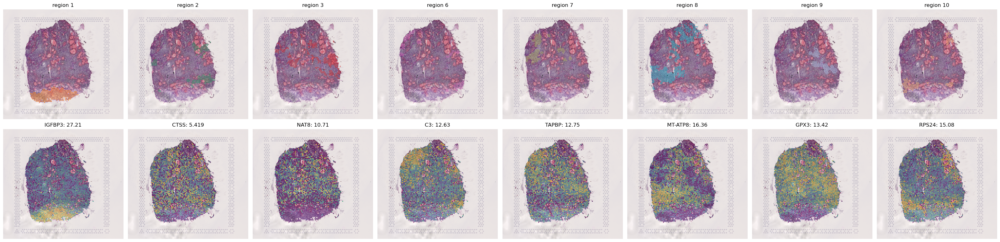

In [49]:
from hyperspot.visualization import plot_domain_svgs

# groups = adata_RCC.obs['leiden'].unique()
groups = sorted(top_gene_list['region'].unique(), key=lambda r: int(r))
plot_domain_svgs(adata_aggr, top_gene_list, groups, n_cols=len(groups), save=True)

In [50]:
groups

['1', '2', '3', '6', '7', '8', '9', '10']

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/

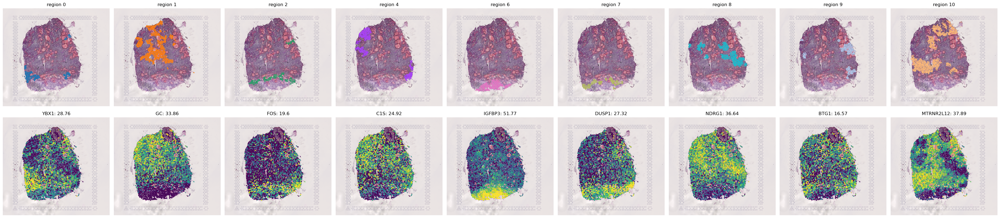

In [51]:
# groups = adata_RCC.obs['leiden'].unique()
groups = sorted(top_genes_RCC_merged['region'].unique(), key=lambda r: int(r))
plot_domain_svgs(adata_RCC, top_genes_RCC_merged, groups, n_cols=12, save=True)

In [52]:
# groups = adata_RCC.obs['leiden'].unique()
# groups = ['2','5','8','11','16','18','20','22']
# plot_domain_svgs(adata_RCC, top_genes_RCC_merged, groups, n_cols=8, save=True)

In [53]:
rcc_svgs = top_genes_RCC_merged.index
tissue_svgs = top_gene_list.index
union = rcc_svgs.union(tissue_svgs)
intersection = rcc_svgs.intersection(tissue_svgs)
len(rcc_svgs), len(tissue_svgs), len(union), len(intersection), len(intersection)/len(union)

(967, 680, 1055, 592, 0.5611374407582939)

In [54]:
top_genes_RCC_merged.loc[rcc_svgs.difference(tissue_svgs)].sort_values("scores",ascending=False)

,scores,adjusted p-vals,region
ENSG00000163814,44.709633,0.000000,6
ENSG00000168824,44.013153,0.000000,6
ENSG00000107317,42.370384,0.000000,6
ENSG00000132329,41.991207,0.000000,6
ENSG00000135919,41.394108,0.000000,6
...,...,...,...
ENSG00000006210,3.639611,0.000409,6
ENSG00000178127,2.824641,0.006539,6
ENSG00000213639,2.607684,0.012300,6
ENSG00000173726,2.270446,0.030206,6


In [55]:
top_gene_list.loc[tissue_svgs.difference(rcc_svgs)].sort_values("scores",ascending=False)

,scores,adjusted p-vals,region
ENSG00000134333,17.437748,4.265585e-66,1
ENSG00000092841,15.336728,2.607322e-51,1
ENSG00000138326,15.084948,2.197112e-47,10
ENSG00000211445,13.415021,1.333248e-37,9
ENSG00000231925,12.745049,1.195869e-33,7
...,...,...,...
ENSG00000104529,2.520965,3.575562e-02,6
ENSG00000022267,2.490654,3.808315e-02,6
ENSG00000189403,2.489605,2.584990e-02,1
ENSG00000136167,2.475957,3.915688e-02,6


/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


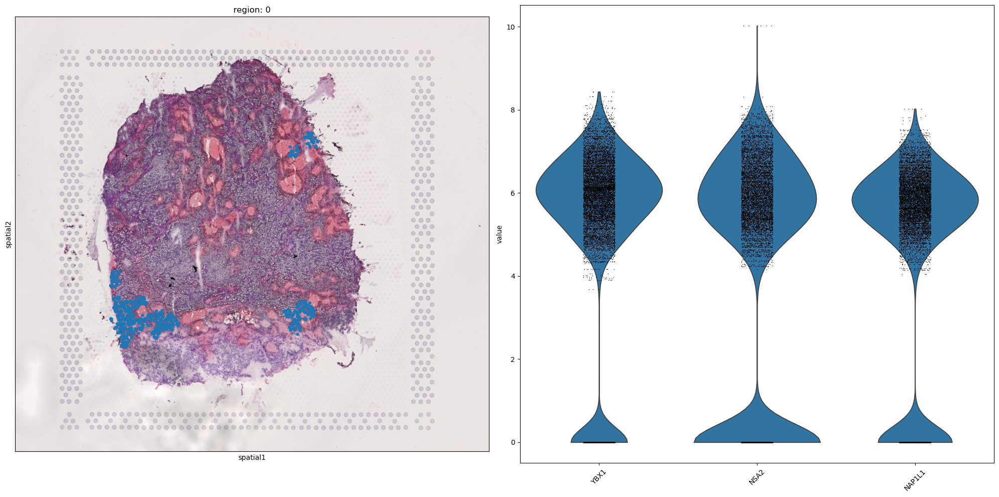

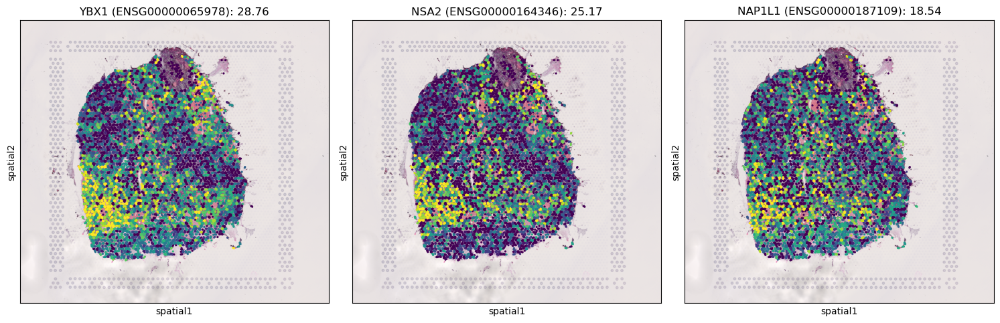

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


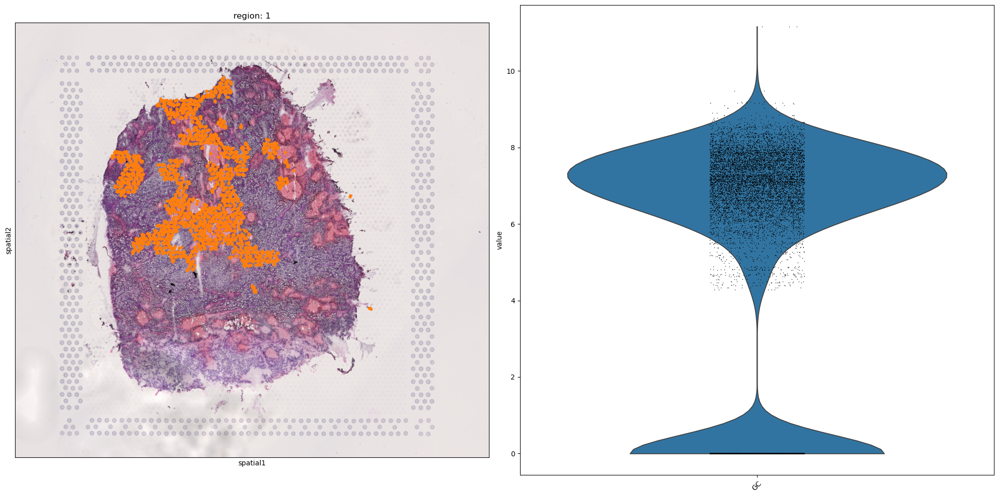

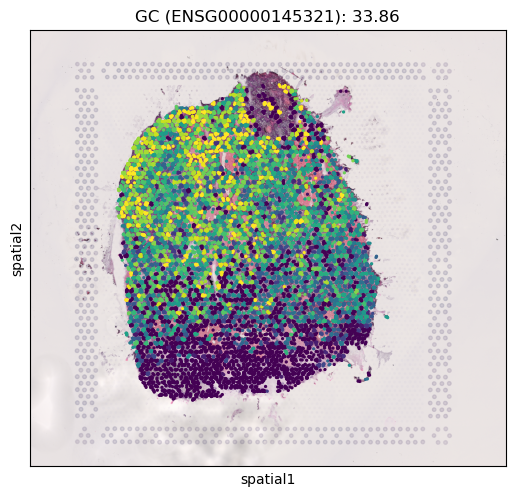

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


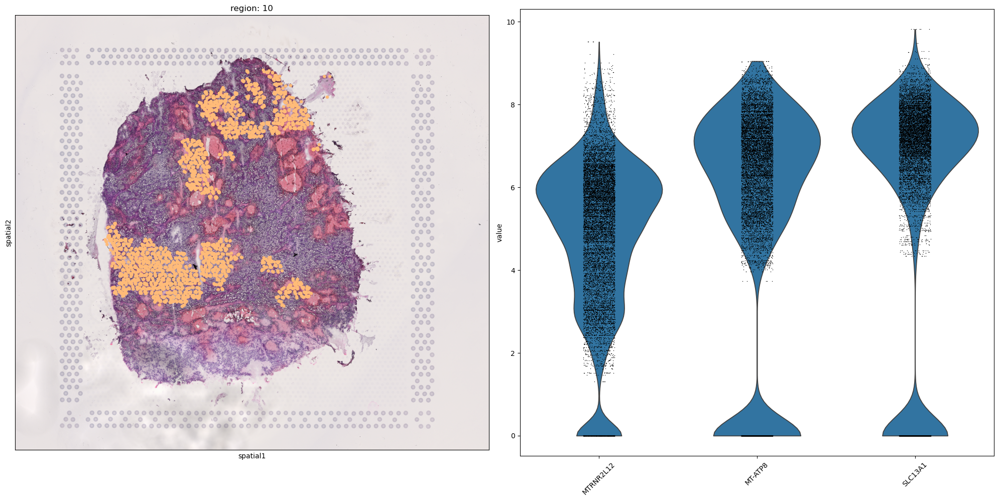

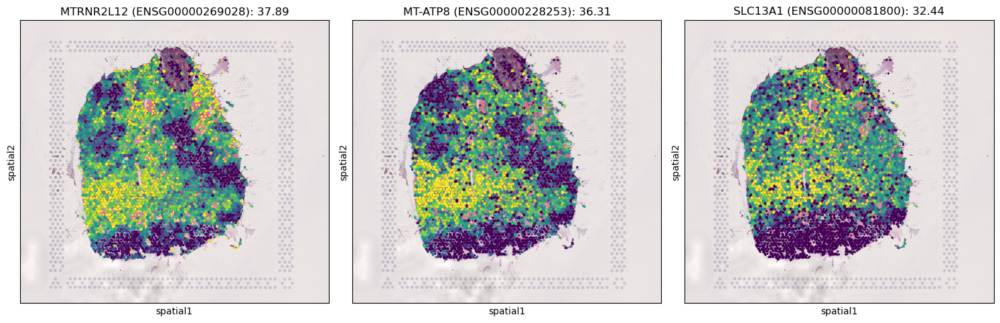

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


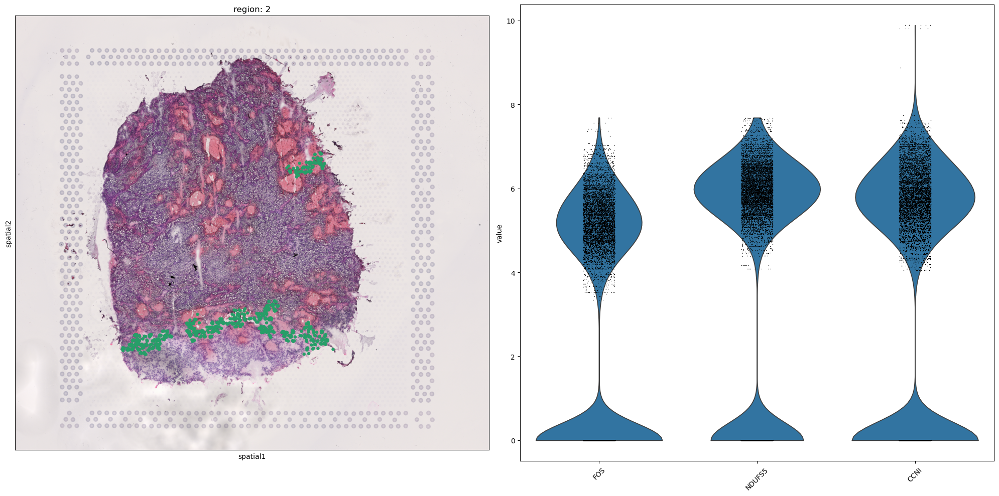

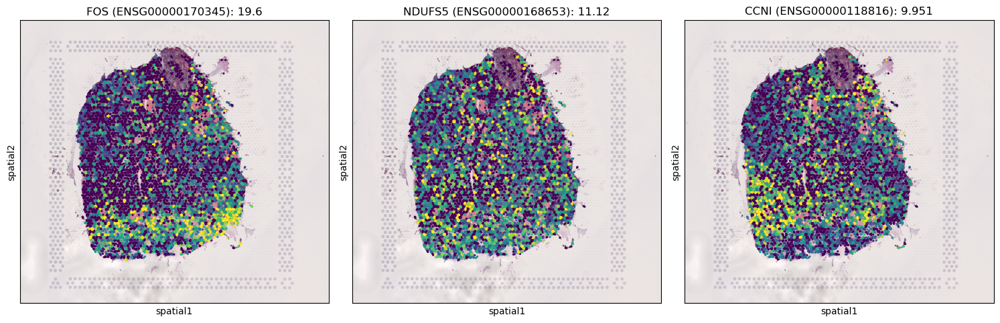

region 3: no ct-SVGs to plot — skipping.


/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


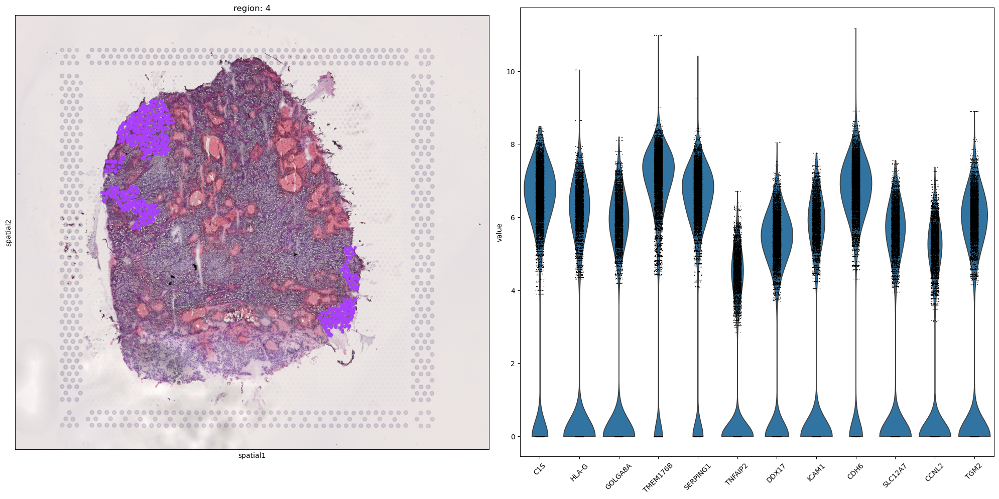

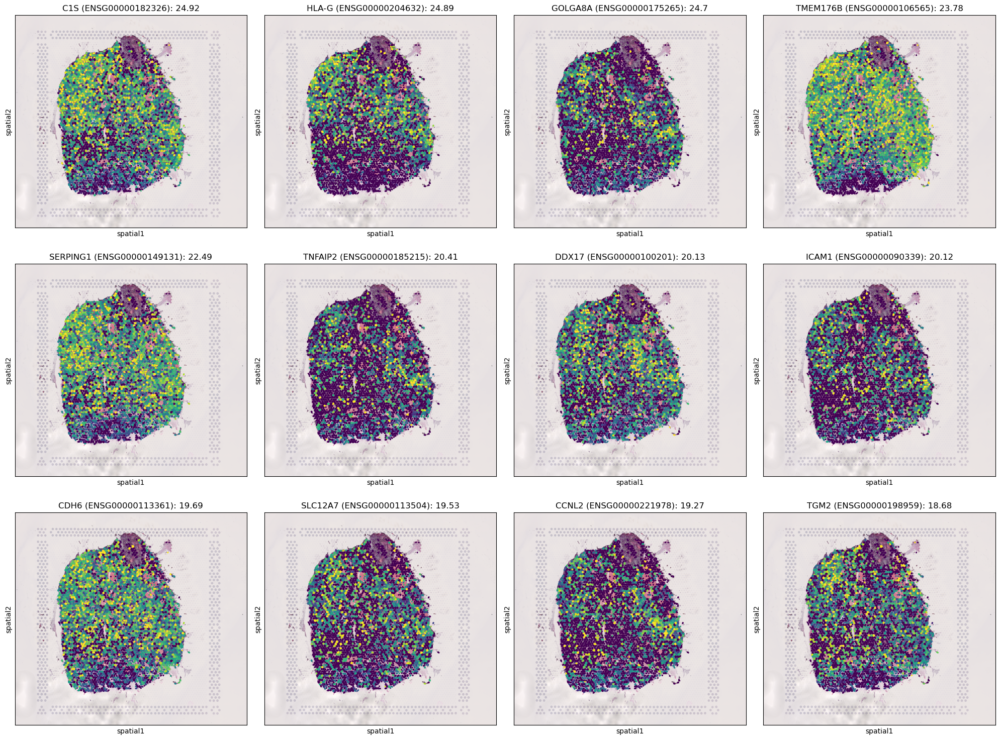

region 5: no ct-SVGs to plot — skipping.


/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


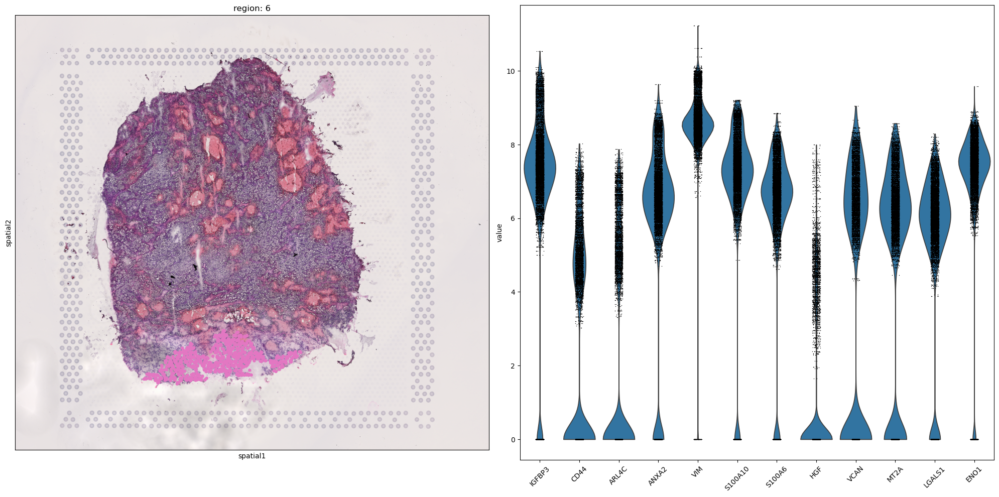

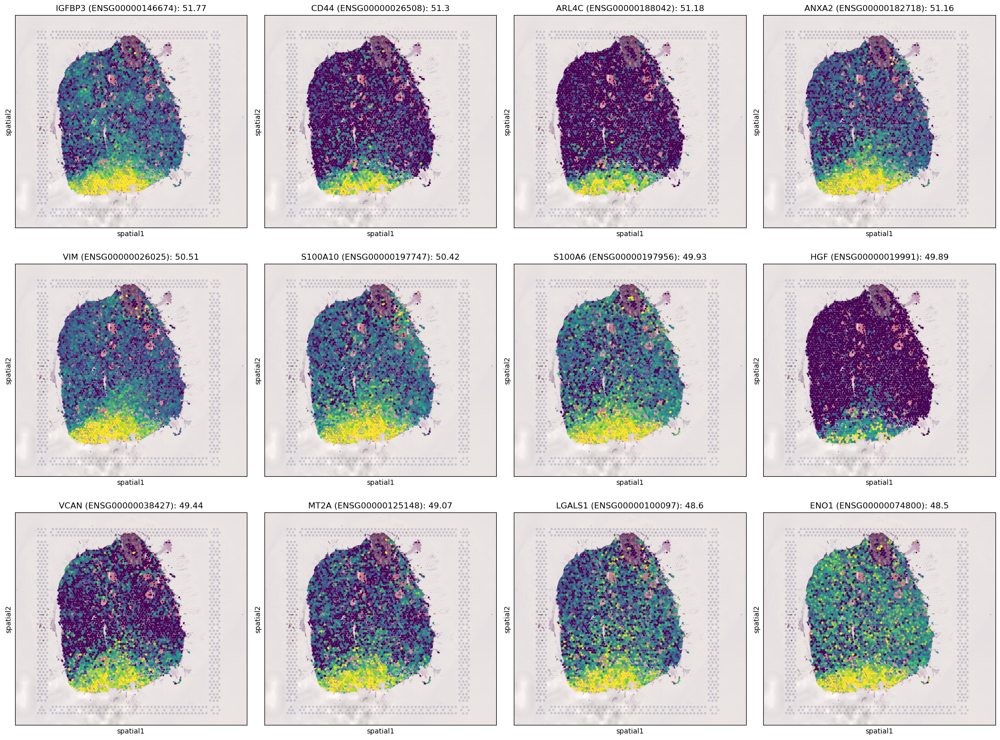

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


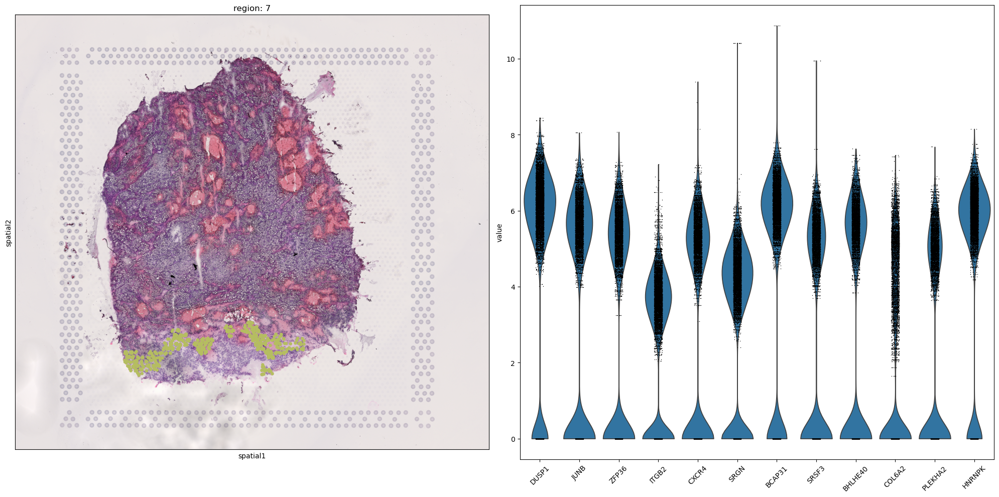

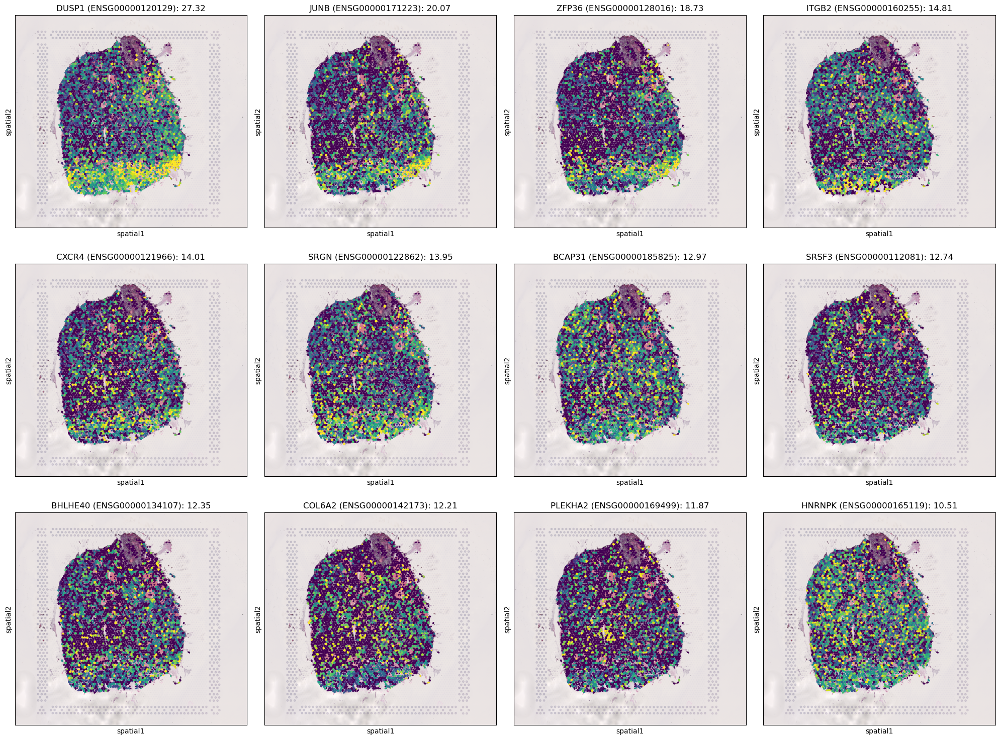

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


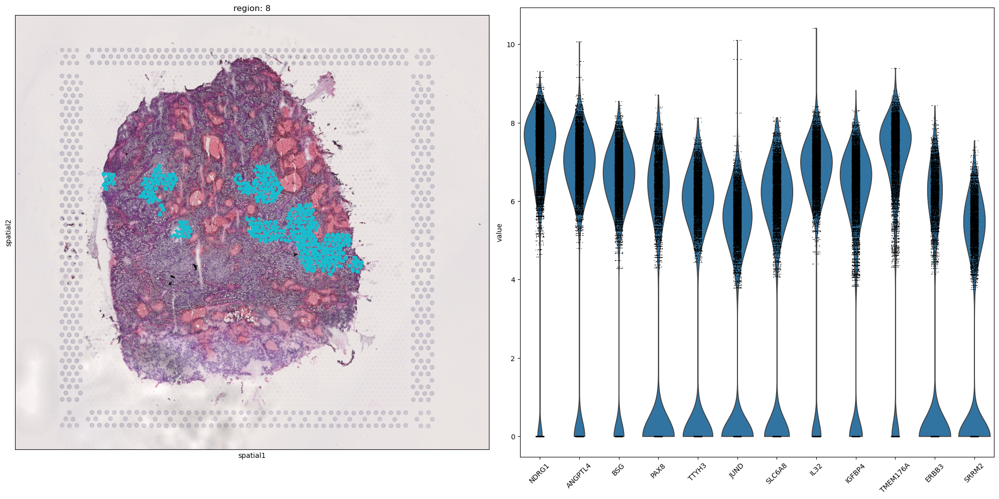

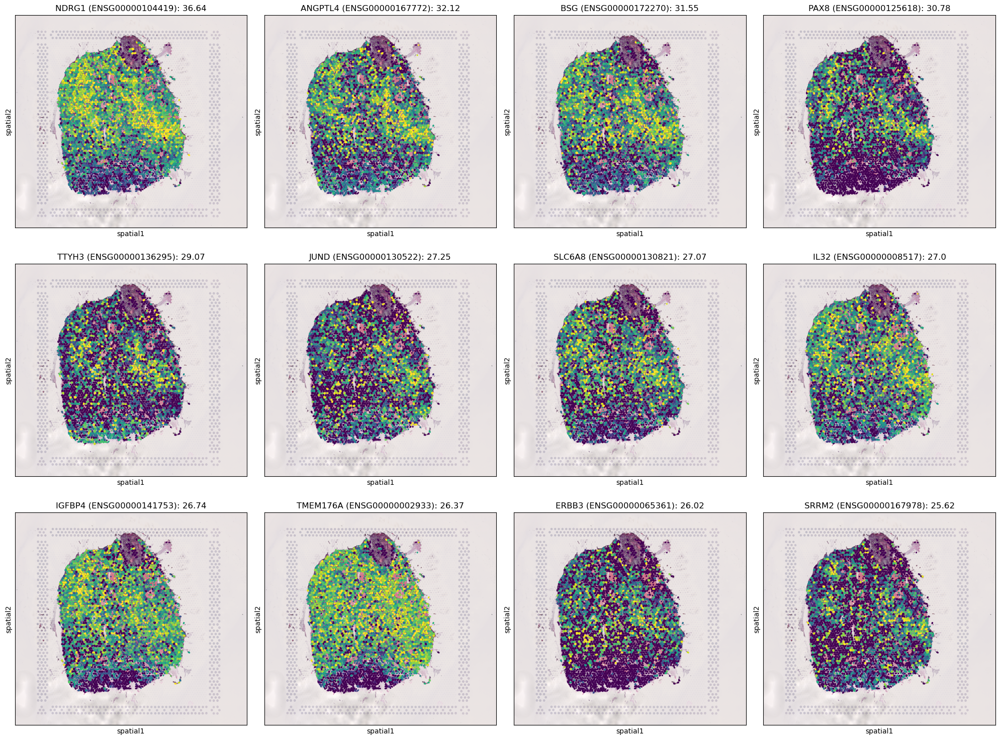

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


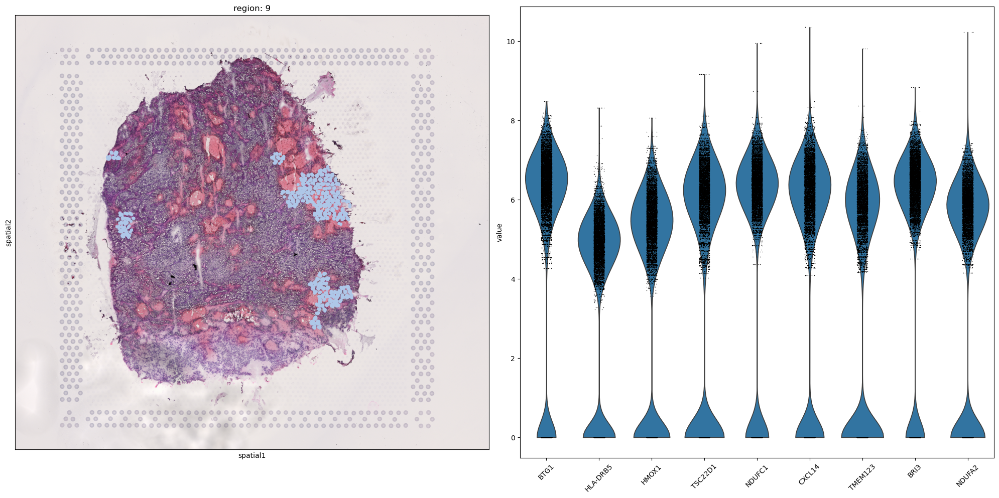

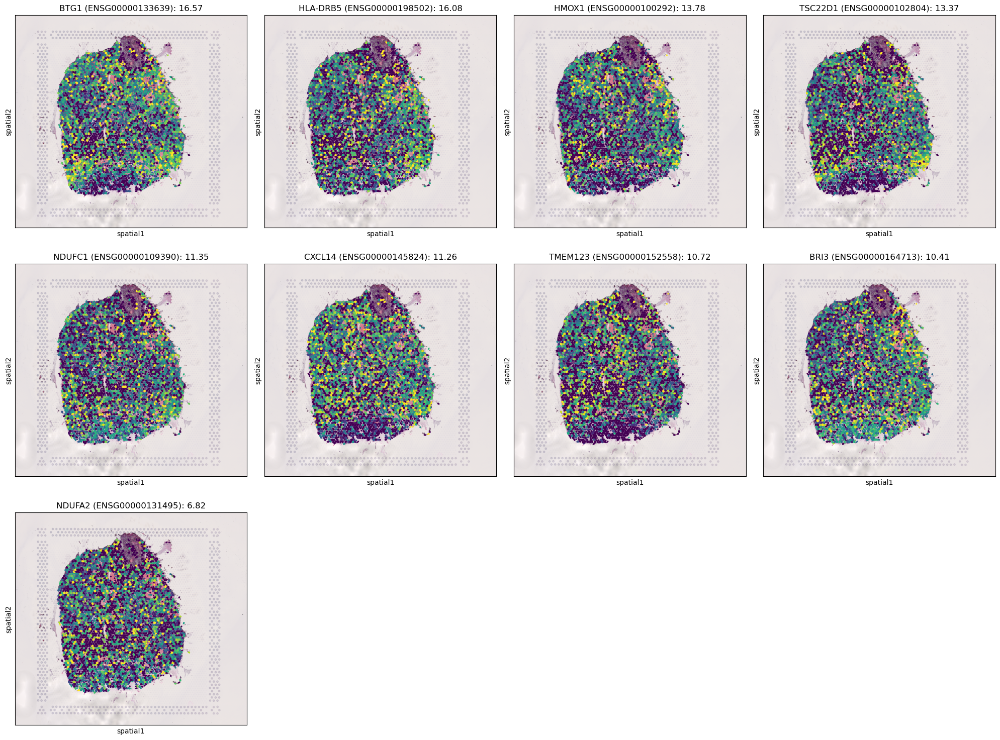

In [56]:
from hyperspot.visualization import plot_domain_ct_svgs
groups = sorted(adata_RCC.obs['domain'].unique())
for g in groups:
    top_genes_RCC_group = top_genes_RCC_merged[top_genes_RCC_merged['region'] == g]
    top_genes_RCC_group = top_genes_RCC_group.sort_values('scores', ascending=False)
    scores = top_genes_RCC_group['scores'].tolist()
    indexes = top_genes_RCC_group.index.tolist()
    plot_domain_ct_svgs(adata_RCC, int(g), scores, indexes, use_raw=False)
    # plot_domain_de_genes(adata_RCC, int(g), top_genes[g]["scores"], top_genes[g]["indexes"], var_names_column='SYMBOL')
    # plot_domain_de_genes(adata_RCC, int(g), list(top_genes_RCC[g]["scores"]), list(top_genes_RCC[g]["names"]), var_names_column='SYMBOL')

In [57]:
1834 / 0.18601191, 2000 / 0.18601191

(9859.583722354122, 10751.999697223688)

(12648, 1)
4.610920306782672 6.734238470447618


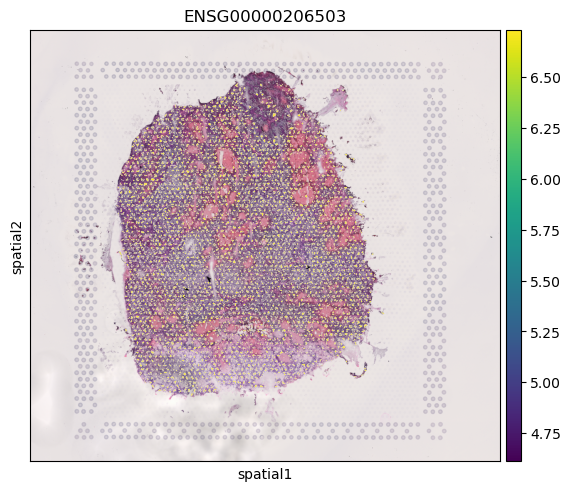

In [58]:
library_id = list(adata_RCC.uns["spatial"].keys())[0]
adata_RCC.uns["spatial"][library_id]["scalefactors"]["tissue_segmentation_scalef"] = 1

vals = adata_RCC[:,'ENSG00000101443'].X
print(vals.shape)
nz = vals[vals > 0]
vmin = np.percentile(nz, 5)
vmax = np.percentile(nz, 95)
print(vmin, vmax)
sq.pl.spatial_segment(
    adata_RCC,
    seg_cell_id="segmentation",
    color='ENSG00000206503',
    library_key='library_id',
    # figsize=(32,32),
    vmin=vmin,
    vmax=vmax,
    # crop_coord=[(1500,900,1800,1500)]
)

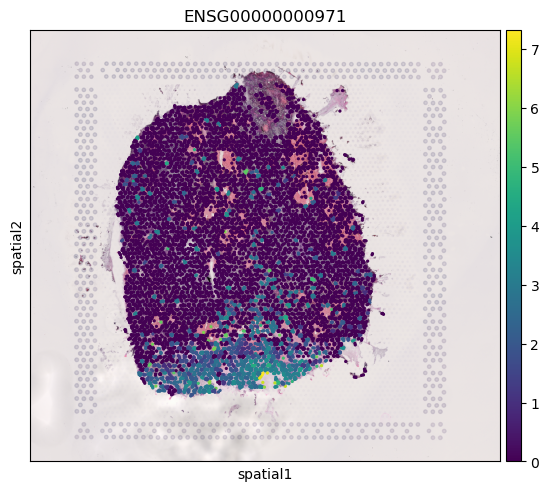

In [59]:
gene_id = 'ENSG00000000971'
vals = adata_RCC[:,gene_id].X
# remove zeros
nz = vals[vals > 0]
vmin = np.percentile(nz, 5)
vmax = np.percentile(nz, 95)

sq.pl.spatial_scatter(
    adata_RCC,
    color=gene_id,
    use_raw=False,
)

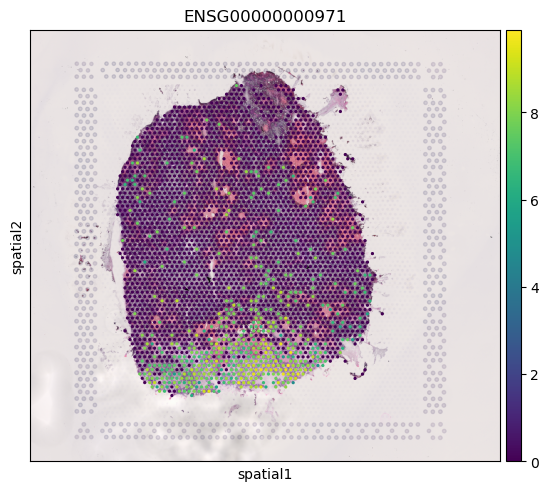

In [60]:
gene_id = 'ENSG00000000971'
vals = adata_aggr[:,gene_id].X
# remove zeros
nz = vals[vals > 0]
vmin = np.percentile(nz, 5)
vmax = np.percentile(nz, 95)

sq.pl.spatial_scatter(
    adata_aggr,
    color=gene_id,
    use_raw=False,
)

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/scanpy/tools/_dendrogram.py:138: UserWarning: You’re trying to run this on 6466 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  _choose_representation(adata, use_rep=use_rep, n_pcs=n_pcs)


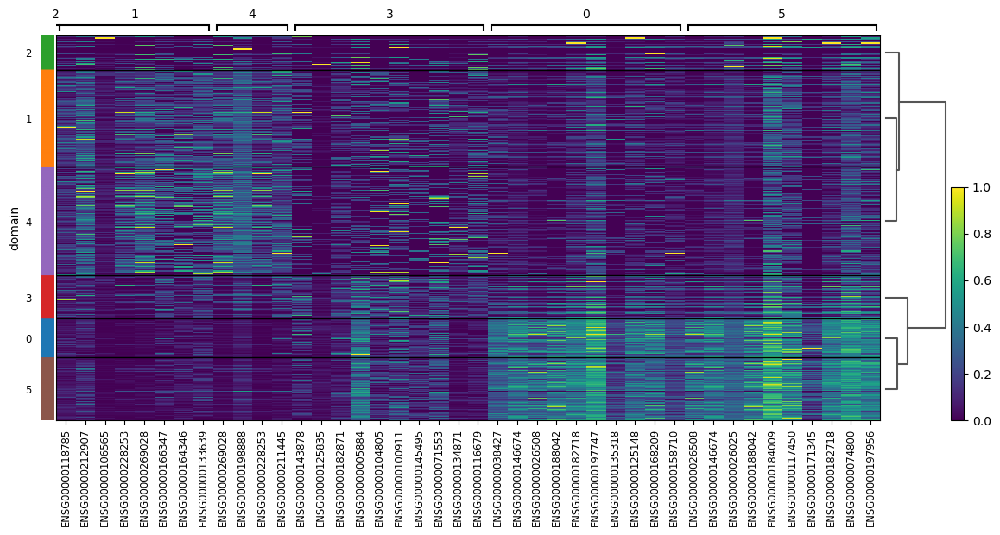

In [61]:
adata_ENPT = load_ct_spatial_data("Epi_non-PT")
top_genes_ENPT = compute_domain_ct_svgs("Epi_non-PT", rank_by='scores')
plot_ct_marker_groups_heatmap(adata_ENPT, top_genes_ENPT)

737 5


/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/

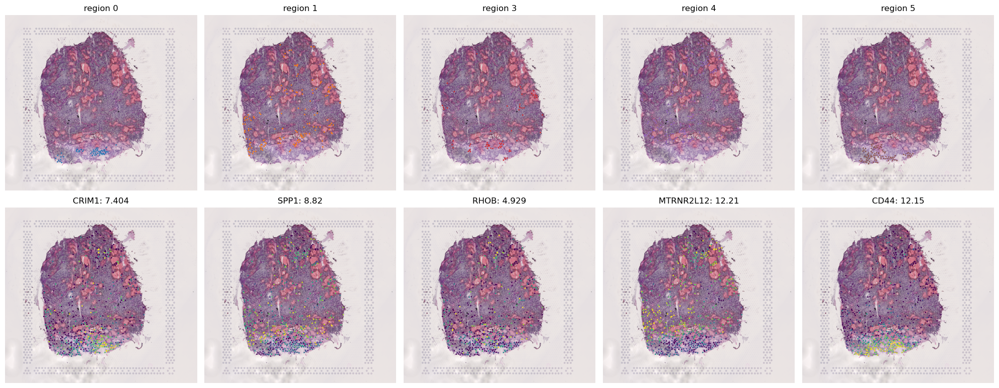

In [62]:
top_genes_ENPT_merged = create_svg_list(top_genes_ENPT)

# groups = adata_RCC.obs['leiden'].unique()
groups = sorted(top_genes_ENPT_merged['region'].unique(), key=lambda r: int(r))
print(len(top_genes_ENPT_merged), len(groups))
plot_domain_svgs(adata_ENPT, top_genes_ENPT_merged, groups, n_cols=len(groups), save=True)

In [63]:
rcc_svgs = top_genes_RCC_merged.index
tissue_svgs = top_gene_list.index
union = rcc_svgs.union(tissue_svgs)
intersection = rcc_svgs.intersection(tissue_svgs)
len(rcc_svgs), len(tissue_svgs), len(union), len(intersection), len(intersection)/len(union)

(967, 680, 1055, 592, 0.5611374407582939)

In [64]:
enpt_svgs = top_genes_ENPT_merged.index
union = enpt_svgs.union(tissue_svgs)
intersection = enpt_svgs.intersection(tissue_svgs)
union_ct = rcc_svgs.union(enpt_svgs)
intersection_ct = rcc_svgs.intersection(enpt_svgs)
len(enpt_svgs), len(tissue_svgs), len(union), len(intersection), len(intersection)/len(union), len(union_ct), len(intersection_ct), len(intersection_ct)/len(union_ct)

(737, 680, 975, 442, 0.4533333333333333, 1020, 684, 0.6705882352941176)

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


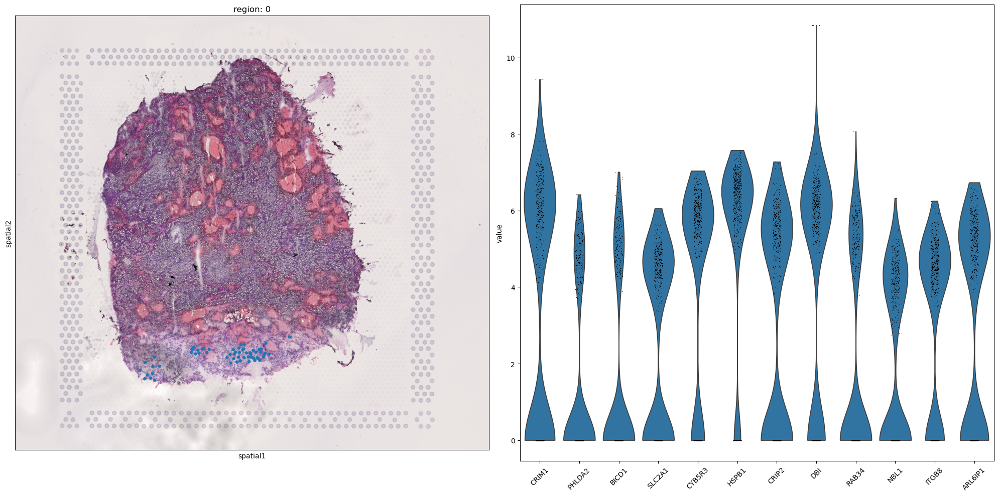

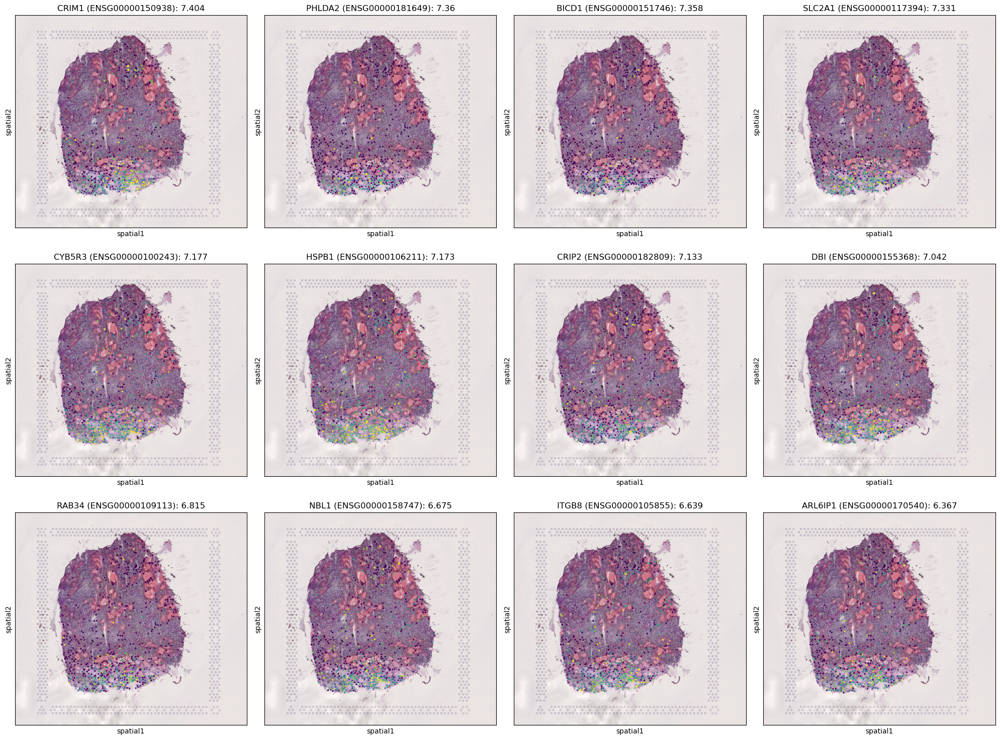

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


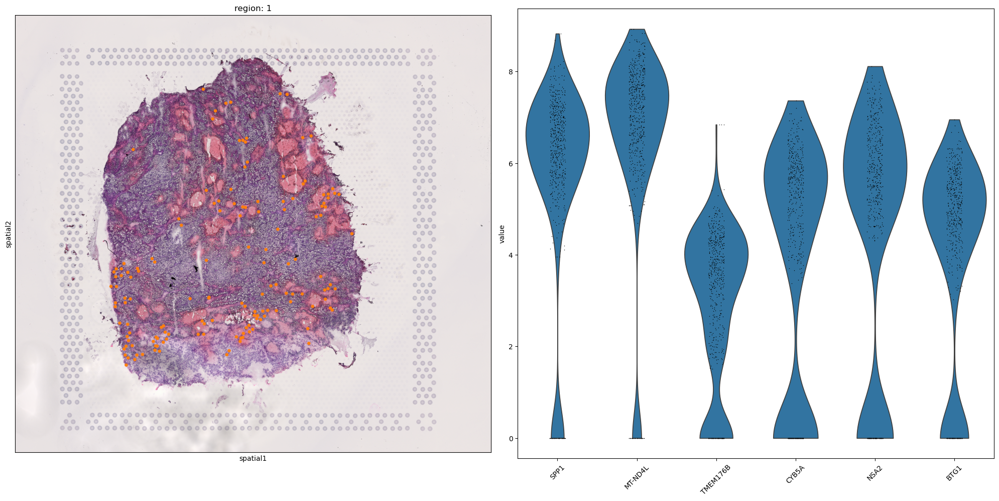

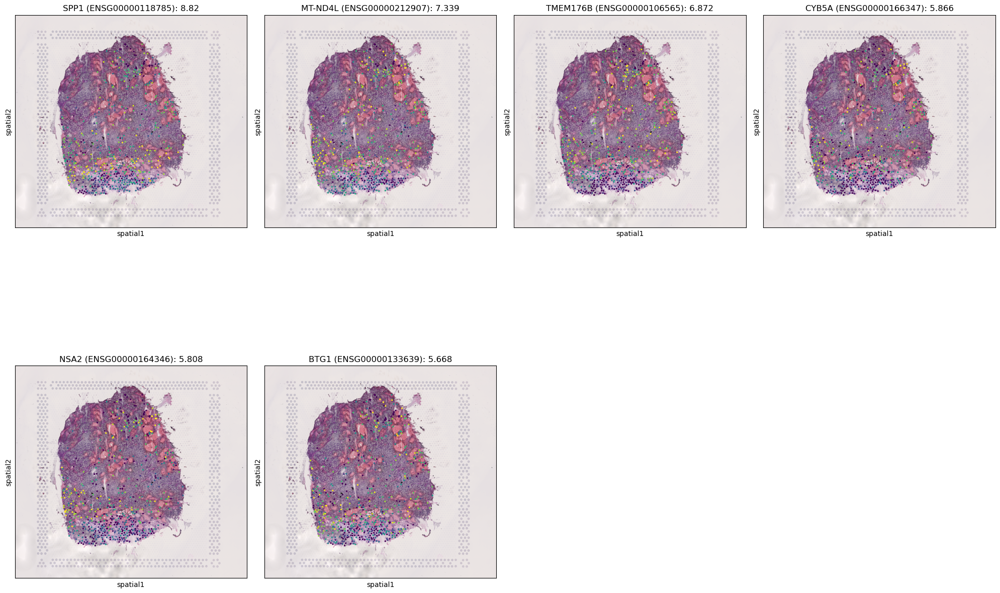

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


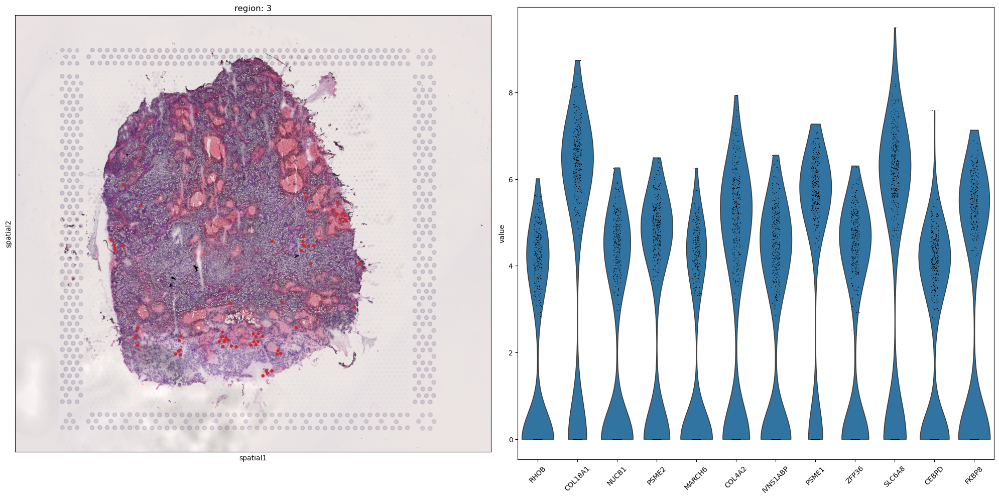

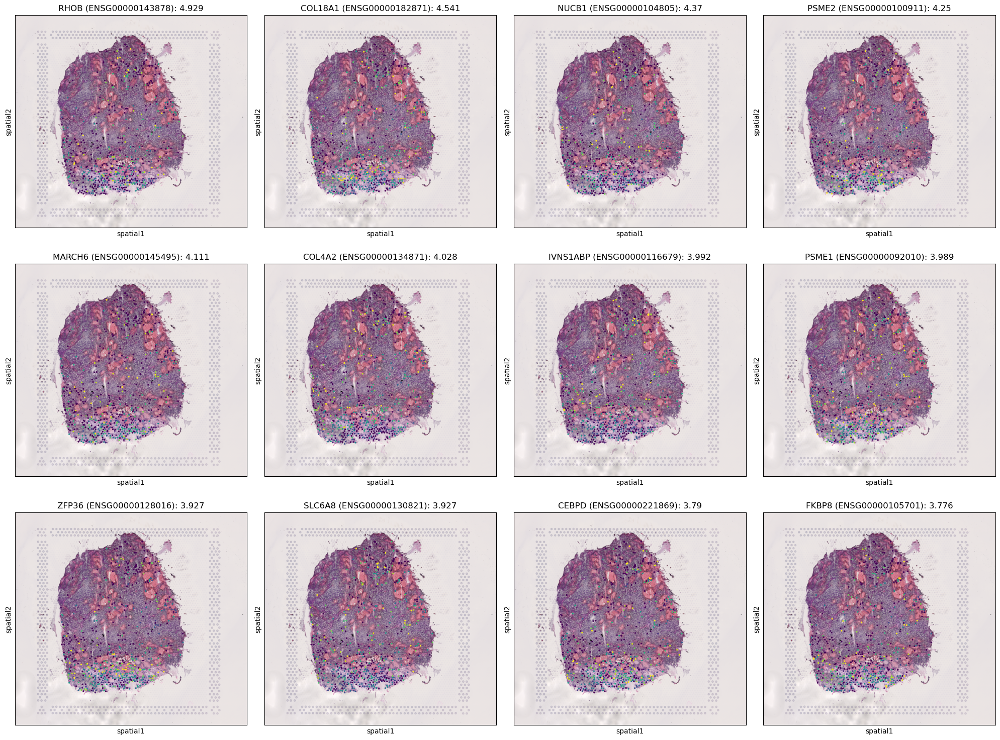

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


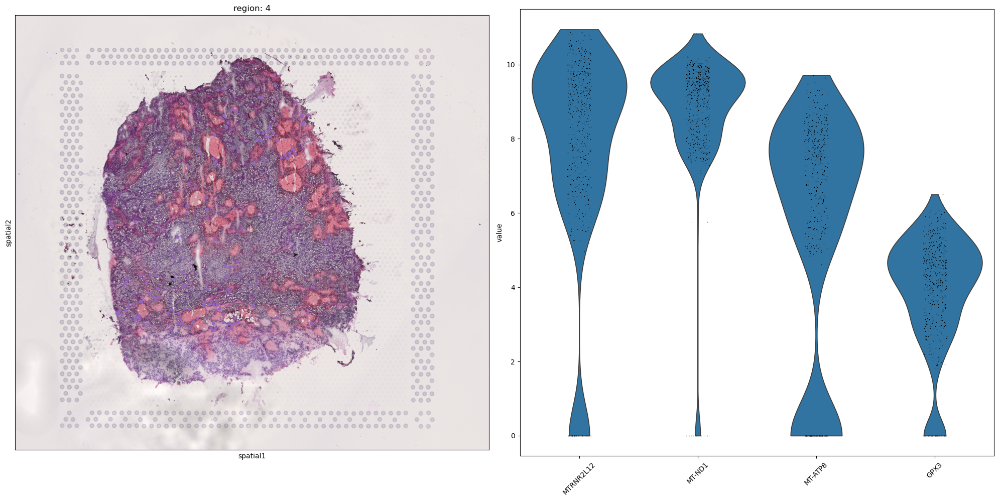

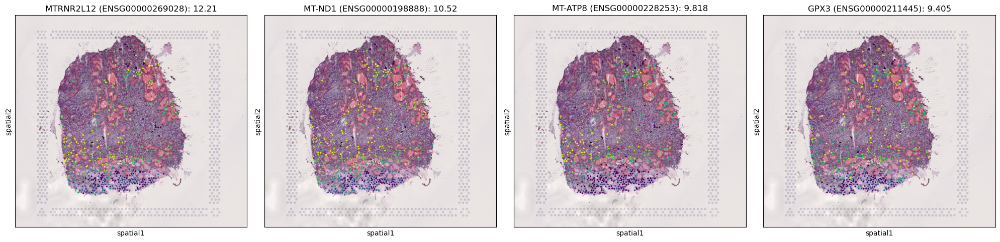

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


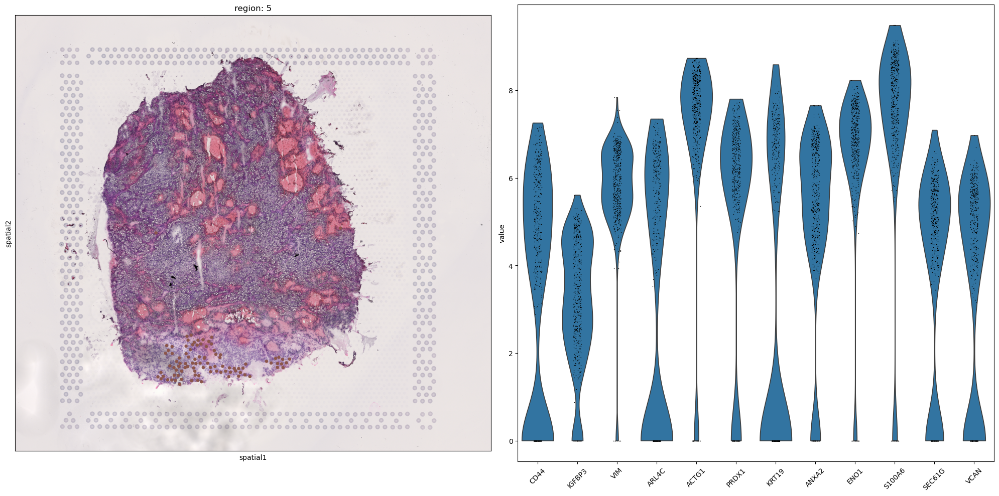

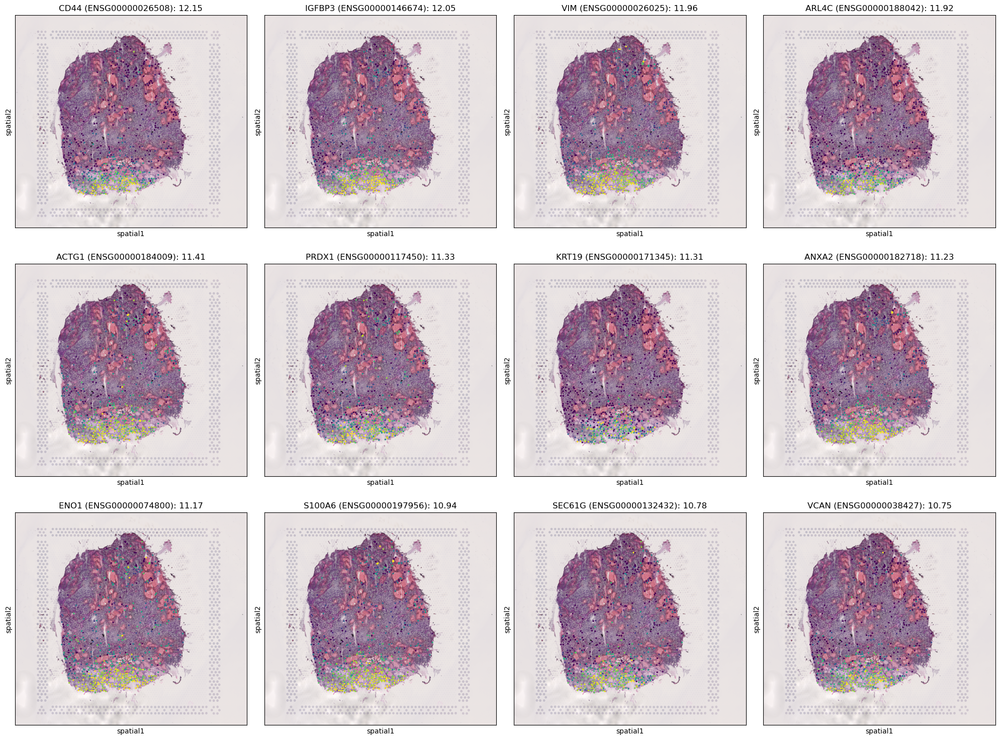

In [65]:
groups = sorted(adata_ENPT.obs['domain'].unique())
for g in groups:
    top_genes_ENPT_group = top_genes_ENPT_merged[top_genes_ENPT_merged['region'] == g]
    top_genes_ENPT_group = top_genes_ENPT_group.sort_values('scores', ascending=False)
    scores = top_genes_ENPT_group['scores'].tolist()
    indexes = top_genes_ENPT_group.index.tolist()
    if len(scores) > 0:
        plot_domain_ct_svgs(adata_ENPT, int(g), scores, indexes, use_raw=False)